# Customer Churn Prediction and Retention Targeting

**Family:** End-to-end project | **Dataset:** `telco_churn` | **Task:** classification

From a ranked churn model to a cost based contact list, with calibration and an honest baseline.

## Table of Contents

- 1. Problem statement
- 2. Business or research context
- 3. Dataset documentation
- 4. Research references
- 5. Exploratory analysis
- 6. Preprocessing
- 7. Model selection
- 8. Model training
- 9. Evaluation
- 10. Comparison
- 11. Interpretation
- 12. Limitations
- 13. Final recommendations

## 1. Problem statement

Predict which telecom customers will leave and decide whom to contact with a retention offer.

## 2. Business or research context

Keeping a customer usually costs less than winning a new one. A retention team has a limited budget, so a good ranking and a justified cut-off matter more than accuracy. The cost numbers below are **assumptions for illustration** (a missed churner costs 5 units, a wasted offer costs 1 unit). Replace them with the real figures of a business before using the cut-off.

## 3. Dataset documentation

**Telco customer churn**, IBM sample data from the repository `IBM/telco-customer-churn-on-icp4d` (code licence Apache-2.0, dataset terms not stated). 7043 customers, 20 features: demographics (`gender`, `SeniorCitizen`, `Partner`, `Dependents`), account (`tenure` in months, `Contract`, `PaperlessBilling`, `PaymentMethod`, `MonthlyCharges`, `TotalCharges`) and services (`PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`). Target `Churn` (1 = customer left). `TotalCharges` has blank strings that become missing values. The file is downloaded once and checked against a SHA-256 hash. Limit: one snapshot, no time dimension. Duplicate rows are reported in the EDA but kept, because without an identifier we cannot tell whether they are different customers.

## 4. Research references

Verification status is from the build environment on 2026-11-17. Entries marked *not verified* must be checked before citing.

- Breiman, L. (2001). *Random Forests*. Machine Learning 45(1):5-32. https://doi.org/10.1023/A:1010933404324 Verification: Crossref 2026-11-17
- Friedman, J. H. (2001). *Greedy function approximation: A gradient boosting machine*. The Annals of Statistics 29(5):1189-1232. https://doi.org/10.1214/aos/1013203451 Verification: Crossref 2026-11-17
- Grinsztajn, L., Oyallon, E. and Varoquaux, G. (2022). *Why do tree-based models still outperform deep learning on tabular data?*. NeurIPS 2022 Datasets and Benchmarks; arXiv:2207.08815. https://arxiv.org/abs/2207.08815 Verification: arXiv abstract page 2026-11-17

These papers cover the model families compared here. None of them uses this dataset, so no number is comparable.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_score
from ml_lab.data import load_dataset
from ml_lab.preprocessing import split_three_way, make_model_pipeline, build_preprocessor
from ml_lab.evaluation import evaluate_estimator, internal_scores, external_scores
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz
PROJECT_ID = "customer_churn"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0


In [2]:
bundle = load_dataset("telco_churn")
X, y = bundle.X, bundle.y
Xtr, Xva, Xte, ytr, yva, yte = split_three_way(X, y, task="classification", seed=SEED)
print("train / validation / test rows:", len(Xtr), len(Xva), len(Xte), "| churn share in train:", round(float(ytr.mean()), 3))
display(pd.Series(bundle.describe_source(), name="source").to_frame())

train / validation / test rows: 4225 1409 1409 | churn share in train: 0.265


,source
title,Telco customer churn
source,"IBM sample data, repository IBM/telco-customer..."
url,https://raw.githubusercontent.com/IBM/telco-cu...
license,"repository is Apache-2.0, dataset terms are no..."
doi,None
rows,7043
features,20
limits,One snapshot with no time dimension. The publi...


## 5. Exploratory analysis

Churn rate, missing values and the link between contract type, tenure and churn.

overall churn rate: 0.265 | duplicate rows: 40 | missing TotalCharges: 11


,mean,count
Contract,,
Month-to-month,0.427,3875
One year,0.113,1473
Two year,0.028,1695


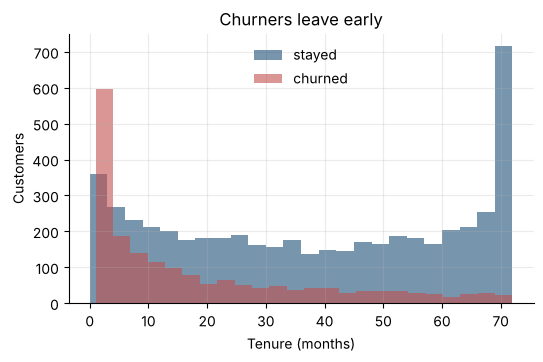

In [3]:
print("overall churn rate:", round(float(y.mean()), 3), "| duplicate rows:", int(X.duplicated().sum()), "| missing TotalCharges:", int(X["TotalCharges"].isna().sum()))
display(pd.concat([X["Contract"], y.rename("churn")], axis=1).groupby("Contract")["churn"].agg(["mean", "count"]).round(3))
fig, ax = plt.subplots(figsize=(6, 3.5))
for v, label in [(0, "stayed"), (1, "churned")]:
    ax.hist(X.loc[y == v, "tenure"], bins=24, alpha=0.6, label=label)
ax.set_xlabel("Tenure (months)"); ax.set_ylabel("Customers"); ax.legend(); ax.set_title("Churners leave early"); plt.show()

## 6. Preprocessing

One preprocessor (median imputation, one hot encoding, scaling for linear models) fitted on training rows only. The test rows are used once at the end.

In [4]:
prep_demo = build_preprocessor(Xtr)
print("encoded feature count:", prep_demo.fit(Xtr).transform(Xva).shape[1])

encoded feature count: 45


## 7. Model selection

Candidates: a logistic regression, a random forest and a histogram gradient boosting model. The primary metric is PR-AUC (area under the precision recall curve) because churn is the minority class. The dummy model gives the floor.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score
candidates = {"dummy": (DummyClassifier(strategy="prior"), True),
              "logistic": (LogisticRegression(max_iter=2000, C=0.5), True),
              "random_forest": (RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=2, random_state=SEED), False),
              "hist_gradient_boosting": (HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, random_state=SEED), False)}
fitted, rows = {}, []
for name, (model, scale) in candidates.items():
    pipe = make_model_pipeline(Xtr, model, scale=scale).fit(Xtr, ytr)
    fitted[name] = pipe
    p = pipe.predict_proba(Xva)[:, 1]
    rows.append({"model": name, "validation_PR_AUC": average_precision_score(yva, p), "validation_ROC_AUC": roc_auc_score(yva, p)})
sel = pd.DataFrame(rows).set_index("model")
display(sel.round(4))
BEST = sel.drop("dummy")["validation_PR_AUC"].idxmax()
print("selected on validation PR-AUC:", BEST)

,validation_PR_AUC,validation_ROC_AUC
model,,
dummy,0.2654,0.5000
logistic,0.6418,0.8359
random_forest,0.6329,0.8352
hist_gradient_boosting,0.6459,0.8367


selected on validation PR-AUC: hist_gradient_boosting


## 8. Model training

The selected model is refit on training plus validation rows. Five fold cross validation on those rows gives the spread of the score.

In [6]:
Xtv, ytv = pd.concat([Xtr, Xva]), pd.concat([ytr, yva])
model, scale = candidates[BEST]
final = make_model_pipeline(Xtv, clone(model), scale=scale).fit(Xtv, ytv)
cv = cross_val_score(make_model_pipeline(Xtv, clone(model), scale=scale), Xtv, ytv, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="average_precision")
print(f"5-fold PR-AUC on train plus validation: {cv.mean():.3f} +- {cv.std(ddof=1):.3f}")

5-fold PR-AUC on train plus validation: 0.667 +- 0.011


## 9. Evaluation

Test set, scored once. Metrics at the default 0.5 threshold and ranking metrics. Then a cost based threshold chosen on the validation rows (with the model trained on the training rows only) and applied to the test rows.

In [7]:
from sklearn.metrics import precision_score, recall_score, f1_score
p_test = final.predict_proba(Xte)[:, 1]
base_p = fitted["dummy"].predict_proba(Xte)[:, 1]
FN_COST, FP_COST = 5.0, 1.0
pv = fitted[BEST].predict_proba(Xva)[:, 1]
grid = np.linspace(0.05, 0.95, 91)
val_cost = [FN_COST * ((pv < t) & (yva == 1)).sum() + FP_COST * ((pv >= t) & (yva == 0)).sum() for t in grid]
THRESH = float(grid[int(np.argmin(val_cost))])
def cost(y_true, score, t):
    return FN_COST * ((score < t) & (y_true == 1)).sum() + FP_COST * ((score >= t) & (y_true == 0)).sum()
test_cost = {"model at cost threshold": cost(yte, p_test, THRESH), "contact nobody": cost(yte, np.zeros(len(yte)), 0.5), "contact everybody": cost(yte, np.ones(len(yte)), 0.5)}
METRICS = {"test_PR_AUC": average_precision_score(yte, p_test), "test_ROC_AUC": roc_auc_score(yte, p_test), "baseline_PR_AUC": average_precision_score(yte, base_p),
           "precision_at_threshold": precision_score(yte, p_test >= THRESH), "recall_at_threshold": recall_score(yte, p_test >= THRESH), "F1_at_threshold": f1_score(yte, p_test >= THRESH),
           "cv_PR_AUC_mean": float(cv.mean()), "cv_PR_AUC_std": float(cv.std(ddof=1)), "cost_model": float(test_cost["model at cost threshold"]), "cost_contact_nobody": float(test_cost["contact nobody"]), "cost_contact_everybody": float(test_cost["contact everybody"])}
CONFIG = {"selected_model": BEST, "threshold": THRESH, "fn_cost": FN_COST, "fp_cost": FP_COST}
EXTRA = {"validation_table": sel.round(4).reset_index().to_dict("records"), "cost_note": "costs are assumptions"}
ALGORITHM = BEST
print("threshold from validation:", round(THRESH, 2)); display(pd.Series(test_cost, name="test cost (assumed units)").round(1).to_frame())

record = ExperimentRecord(notebook=PROJECT_ID, family="project", algorithm=ALGORITHM, dataset="telco_churn", task="classification", seed=SEED, config=CONFIG, metrics=METRICS, extra=EXTRA)
print("saved:", record.save())
display(pd.Series(METRICS, name="metric").round(4).to_frame())

threshold from validation: 0.18


,test cost (assumed units)
model at cost threshold,625.0
contact nobody,1870.0
contact everybody,1035.0


saved: /home/claude/open-python/experiments/results/customer_churn.json


,metric
test_PR_AUC,0.6607
test_ROC_AUC,0.8449
baseline_PR_AUC,0.2654
precision_at_threshold,0.4687
recall_at_threshold,0.8610
F1_at_threshold,0.6070
cv_PR_AUC_mean,0.6670
cv_PR_AUC_std,0.0114
cost_model,625.0000
cost_contact_nobody,1870.0000


## 10. Comparison

All candidates on the same test rows (this table is for comparison only, the choice was made on validation rows) and a calibration check of the selected model.

,test_PR_AUC,test_ROC_AUC
model,,
dummy,0.2654,0.5000
logistic,0.6346,0.8427
random_forest,0.6427,0.8399
hist_gradient_boosting,0.6577,0.8431


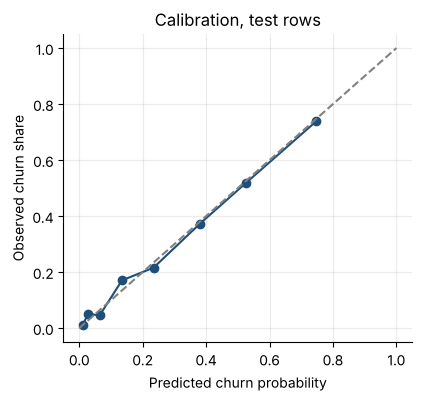

In [8]:
rows = []
for name, pipe in fitted.items():
    pr = pipe.predict_proba(Xte)[:, 1]
    rows.append({"model": name, "test_PR_AUC": average_precision_score(yte, pr), "test_ROC_AUC": roc_auc_score(yte, pr)})
display(pd.DataFrame(rows).set_index("model").round(4))
from sklearn.calibration import calibration_curve
frac, mean_pred = calibration_curve(yte, p_test, n_bins=8, strategy="quantile")
fig, ax = plt.subplots(figsize=(4.5, 4)); ax.plot(mean_pred, frac, marker="o"); ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set_xlabel("Predicted churn probability"); ax.set_ylabel("Observed churn share"); ax.set_title("Calibration, test rows"); save_figure(fig, PROJECT_ID, "calibration"); plt.show()

## 11. Interpretation

Permutation importance on the test rows (drop in PR-AUC when one column is shuffled) shows what the ranking depends on.

In [9]:
imp = permutation_importance(final, Xte, yte, scoring="average_precision", n_repeats=5, random_state=SEED, n_jobs=1)
display(pd.Series(imp.importances_mean, index=Xte.columns).sort_values(ascending=False).head(8).round(4).to_frame("PR-AUC drop"))

,PR-AUC drop
tenure,0.1212
Contract,0.0889
TotalCharges,0.0252
TechSupport,0.0223
InternetService,0.0192
MonthlyCharges,0.0145
OnlineSecurity,0.0135
PaymentMethod,0.0065


## 12. Limitations

One snapshot with no time dimension, so we cannot test drift. The cost numbers are assumptions. Duplicates were kept. The data has no information about what offers work, so the model ranks risk but does not say which action to take (that needs an experiment with a control group).

## 13. Final recommendations

Use the model to rank customers, not to decide actions alone. Validate the cost ratio with the retention team, check calibration on fresh data every month, and run a controlled retention test before scaling.